# Part 4 — What Drives Default, and What Should a Lender Do?
**Beyond Credit Scores: Discovering Borrower Risk Profiles and Early Warning Patterns for Loan Default**
DSAI 4102 Applied Data Mining · Group 1 · Amal Haji (60100554)

Parts 1–3 found patterns: early-warning rules and six borrower profiles that hold up under testing. This notebook
uses two supervised models, **Logistic Regression** and **Random Forest**, to *explain* those patterns, not to win
on accuracy. It then tests the project's main claim and turns the results into lender actions.

| Section | Aim |
|---|---|
| 4.1 | Split loans by time: learn from 2007–2013, test on 2014–2015 |
| 4.2 | Which features push default up or down? (Logistic Regression) |
| 4.3 | Does a non-linear model agree? (Random Forest) |
| 4.4 | Do different profiles default for different reasons? |
| 4.5 | Do the profiles add information on top of Lending Club's grade? |
| 4.6 | How well do the models rank risk? (supporting metrics) |
| 4.7 | What should a lender do? |

**Outputs:** `figures/04_*.png`, `data/processed/model_comparison.csv`

## Setup

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import chi2
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    log_loss,
    precision_recall_fscore_support,
)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

TRAIN_LAST_YEAR = 2013  # same time split as Part 1b
REVIEW_SHARE = 0.20  # a lender reviews the riskiest 20% of applications by hand
IMPORTANCE_SAMPLE = 30_000  # permutation importance re-scores the model many times, so it uses a 30k sample
MIN_CELL = 200  # grade x profile cells with fewer loans are hidden (too noisy)

plt.rcParams.update(
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}
)
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#52514e"

fs = json.loads((DATA_DIR / "feature_sets.json").read_text())
SEED = fs["random_state"]
FEATURES = fs["cluster_numeric"]

df = pd.read_parquet(DATA_DIR / fs["data_file"])
df = df.merge(pd.read_csv(DATA_DIR / "clusters_kmeans.csv"), on="id")
# 1 Established homeowners ... 6 Stretched borrowers
names = df.groupby("profile")["profile_name"].first()
print(f"{len(df):,} loans with their Part 2 profile")

673,314 loans with their Part 2 profile


## 4.1 Split by time
**Aim:** test every model the way a lender would use it, trained on past loans and judged on later ones.

In [2]:
# 1) Learn from loans issued up to 2013, test on 2014-2015 (stricter than a random split, which mixes years).
train = df[df["issue_year"] <= TRAIN_LAST_YEAR].copy()
test = df[df["issue_year"] > TRAIN_LAST_YEAR].copy()

# 2) Standardise the features using the TRAIN loans only, so nothing about the test years leaks in.
#    After this, every coefficient means "effect of +1 standard deviation", so features can be compared.
scaler = StandardScaler().fit(train[FEATURES])
train[FEATURES] = scaler.transform(train[FEATURES])
test[FEATURES] = scaler.transform(test[FEATURES])

print(
    f"train: {len(train):,} loans, {train['default'].mean():.1%} default | "
    f"test: {len(test):,} loans, {test['default'].mean():.1%} default"
)
# The profiles came from clustering all years at once. That's not leakage: clustering never sees the
# default label, it only groups borrowers by their application data.

train: 227,957 loans, 15.5% default | test: 445,357 loans, 14.5% default


## 4.2 Which features push default up or down?
**Aim:** a Logistic Regression gives one interpretable number per feature, the odds ratio.

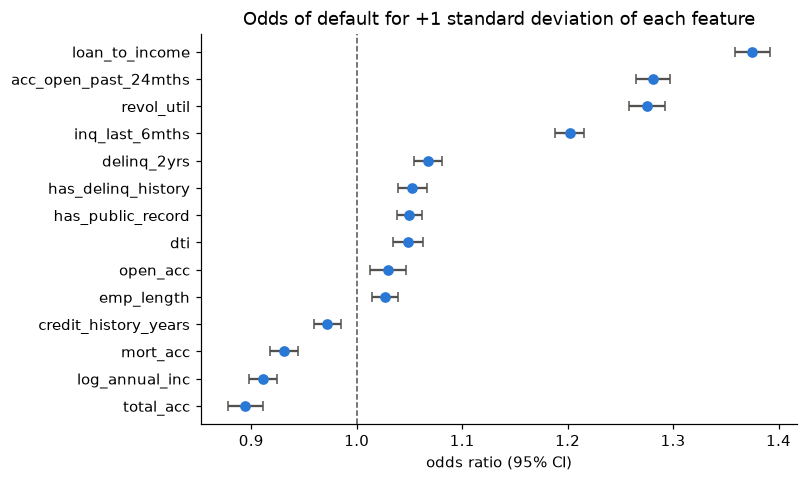

,odds_ratio,low,high
total_acc,0.894,0.878,0.911
log_annual_inc,0.911,0.897,0.924
mort_acc,0.931,0.918,0.944
credit_history_years,0.972,0.959,0.985
emp_length,1.027,1.014,1.039
open_acc,1.030,1.012,1.047
dti,1.049,1.035,1.063
has_public_record,1.050,1.038,1.062
has_delinq_history,1.053,1.039,1.066
delinq_2yrs,1.068,1.055,1.081


In [3]:
# 1) Fit on the train loans. statsmodels also gives a 95% confidence interval for every coefficient.
#    No class weighting here (unlike the forest in 4.3): weighting would distort the odds ratios and the
#    predicted probabilities, and reading those on their real scale is the whole point of this model.
logit = sm.Logit(train["default"], sm.add_constant(train[FEATURES])).fit(disp=0)

# 2) Odds ratio = exp(coefficient): the change in the odds of default for +1 standard deviation of a feature.
#    1.20 = odds up 20%; 0.85 = odds down 15%; an interval that crosses 1 = no clear effect.
odds = (
    pd.DataFrame(
        {
            "odds_ratio": np.exp(logit.params),
            "low": np.exp(logit.conf_int()[0]),
            "high": np.exp(logit.conf_int()[1]),
        }
    )
    .drop("const")
    .sort_values("odds_ratio")
)

fig, ax = plt.subplots(figsize=(7, 4.6))
ax.errorbar(
    odds["odds_ratio"],
    odds.index,
    xerr=[odds["odds_ratio"] - odds["low"], odds["high"] - odds["odds_ratio"]],
    fmt="o",
    color=BLUE,
    ecolor=GREY,
    capsize=3,
)
ax.axvline(1, color=GREY, linestyle="--", linewidth=1)
ax.set(
    title="Odds of default for +1 standard deviation of each feature",
    xlabel="odds ratio (95% CI)",
)
fig.savefig(FIG_DIR / "04_odds_ratios.png", dpi=200, bbox_inches="tight")
plt.show()
odds.round(3)

**Finding.** Every feature has a clear effect (no interval crosses 1). The four strongest risk-raisers are **loan-to-income** (odds ×1.38 per standard deviation), **new accounts in the last 24 months** (×1.28), **revolving utilisation** (×1.28) and **recent credit inquiries** (×1.20). The strongest protective features are more accounts in total (×0.89), higher income (×0.91) and mortgage accounts (×0.93). This matches Part 1b's early-warning rules: borrowing a lot relative to income while actively seeking new credit. One caution: `open_acc` (×1.03) and `total_acc` (×0.89) are correlated (r = 0.69), so their separate effects should be read together, not one at a time.

## 4.3 Does a non-linear model agree?
**Aim:** a Random Forest can pick up thresholds and interactions that a straight-line model misses.
If both models rank the same features at the top, the drivers are trustworthy.

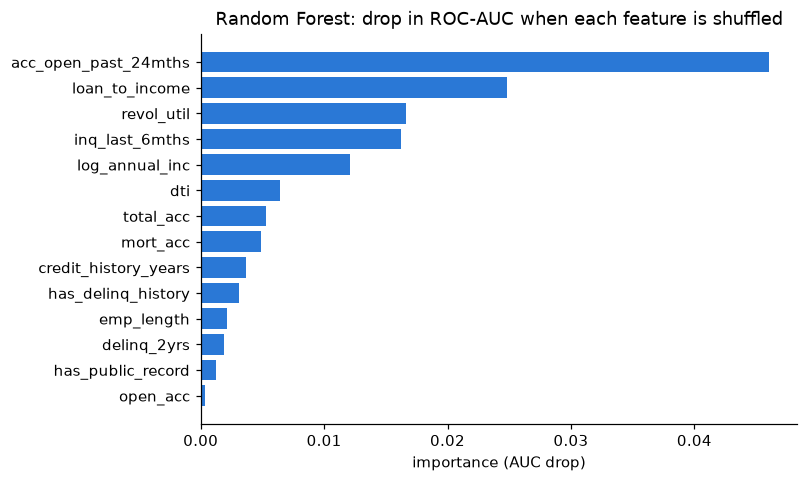

,Logistic Regression (|log odds ratio|),Random Forest (permutation)
1,loan_to_income,acc_open_past_24mths
2,acc_open_past_24mths,loan_to_income
3,revol_util,revol_util
4,inq_last_6mths,inq_last_6mths
5,total_acc,log_annual_inc


In [4]:
# 1) Fit the forest. min_samples_leaf=50 stops trees memorising single loans; class_weight balances the
#    ~15% defaults against the ~85% paid-off loans so the trees don't just learn "never default".
forest = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=50,
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=SEED,
).fit(train[FEATURES], train["default"])

# 2) Permutation importance on test loans: shuffle one feature at a time and measure how much ROC-AUC drops.
#    The forest's built-in importance favours features with many distinct values, so it can mislead.
sample = test.sample(IMPORTANCE_SAMPLE, random_state=SEED)
perm = permutation_importance(
    forest,
    sample[FEATURES],
    sample["default"],
    scoring="roc_auc",
    n_repeats=3,
    random_state=SEED,
    n_jobs=-1,
)
importance = pd.Series(perm.importances_mean, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(importance.index, importance.values, color=BLUE)
ax.set(
    title="Random Forest: drop in ROC-AUC when each feature is shuffled",
    xlabel="importance (AUC drop)",
)
fig.savefig(FIG_DIR / "04_rf_importance.png", dpi=200, bbox_inches="tight")
plt.show()

# 3) Side by side: the top 5 features in each model.
lr_strength = (np.log(odds["odds_ratio"]).abs()).sort_values(ascending=False)
pd.DataFrame(
    {
        "Logistic Regression (|log odds ratio|)": lr_strength.index[:5],
        "Random Forest (permutation)": importance.sort_values(ascending=False).index[
            :5
        ],
    },
    index=range(1, 6),
)

**Finding.** The two models agree. The same four features (new accounts, loan-to-income, utilisation, recent inquiries) top both lists, just in a slightly different order, so these drivers are not an artefact of one model's assumptions. Random Forest also scores almost exactly like Logistic Regression on new loans (ROC-AUC 0.647 vs 0.646, section 4.6), so there is no strong hidden non-linear signal that the simpler, more explainable model misses.

## 4.4 Do different profiles default for different reasons?
**Aim:** fit a separate Logistic Regression inside each profile and compare the coefficients.

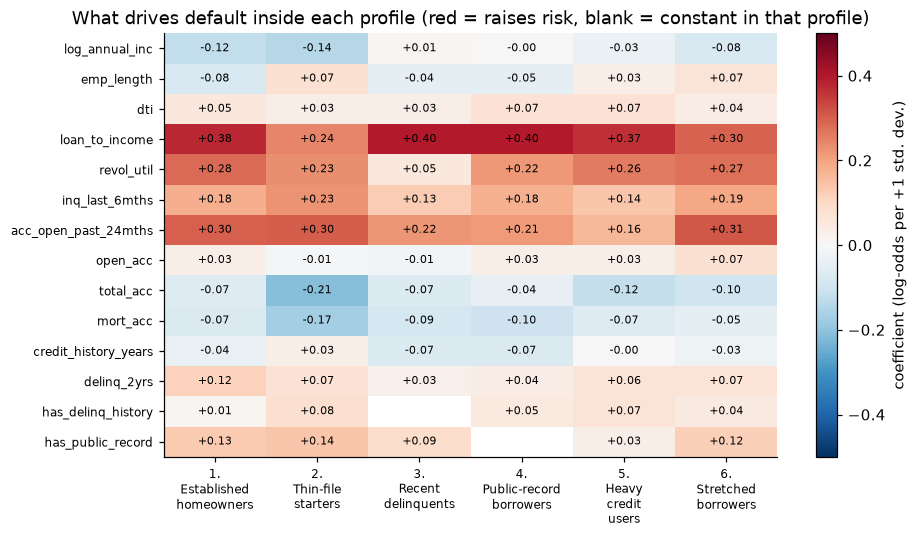

In [5]:
# 1) One model per profile, on that profile's train loans only.
# 2) A feature that never changes inside a profile (e.g. has_public_record is 1 for everyone in profile 4)
#    can't be estimated there, so it is left out of that profile's model and shown as blank.
coefs = {}
for p, group in train.groupby("profile"):
    usable = [f for f in FEATURES if group[f].std() > 0.01]
    model = sm.Logit(group["default"], sm.add_constant(group[usable])).fit(disp=0)
    coefs[f"{p}. {names[p]}"] = model.params.drop("const")
coefs = pd.DataFrame(coefs).reindex(FEATURES)

fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(coefs, cmap="RdBu_r", vmin=-0.5, vmax=0.5, aspect="auto")
ax.set_xticks(
    range(len(coefs.columns)), [c.replace(" ", "\n") for c in coefs.columns], fontsize=8
)
ax.set_yticks(range(len(FEATURES)), FEATURES, fontsize=8)
for (i, j), v in np.ndenumerate(coefs.values):
    if not np.isnan(v):
        ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, label="coefficient (log-odds per +1 std. dev.)")
ax.set_title(
    "What drives default inside each profile (red = raises risk, blank = constant in that profile)"
)
fig.savefig(FIG_DIR / "04_drivers_by_profile.png", dpi=200, bbox_inches="tight")
plt.show()

**Finding.** The core drivers are shared, but their strength differs by profile. **Loan-to-income** raises risk in every profile, most for Recent delinquents and Public-record borrowers (+0.40) and least for Thin-file starters (+0.24). **Utilisation** matters in five profiles (+0.22 to +0.28) but barely for Recent delinquents (+0.05): once someone has recently missed payments, how much of their card limit they use adds little. For **Thin-file starters**, having more accounts (−0.21) and a mortgage (−0.17) protects far more than in any other profile: for a short credit history, every established account counts. And for **Established homeowners**, a recent missed payment (+0.12) weighs more than anywhere else: a slip stands out on an otherwise clean record. So one scorecard for everyone would under- or over-weight some signals for some borrowers.

## 4.5 Do the profiles add information on top of Lending Club's grade?
**Aim:** the "Beyond Credit Scores" test. Grade is Lending Club's own risk score. If two profiles in the *same*
grade default at different rates, the grade is missing something our profiles capture.

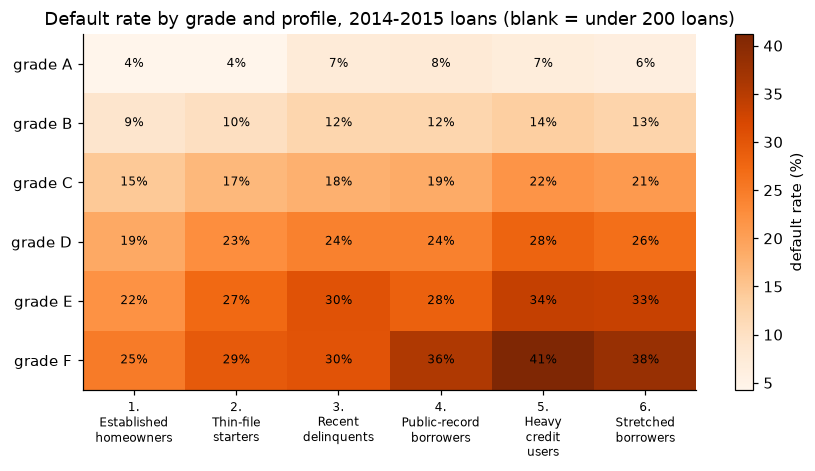

,1. Established homeowners,2. Thin-file starters,3. Recent delinquents,4. Public-record borrowers,5. Heavy credit users,6. Stretched borrowers
grade,,,,,,
A,4.3,4.4,7.2,7.6,6.8,6.2
B,9.0,10.3,12.3,12.3,13.6,12.5
C,14.5,16.7,17.7,18.5,21.7,20.8
D,18.8,22.5,24.3,24.2,28.0,26.5
E,21.9,27.3,30.4,28.4,33.8,33.4
F,25.0,29.4,30.3,35.7,41.2,38.1


In [6]:
# 1) Default rate for every grade x profile combination, on the test loans.
counts = pd.crosstab(test["grade"], test["profile"])
rates = (
    pd.crosstab(test["grade"], test["profile"], values=test["default"], aggfunc="mean")
    * 100
)
# hide cells under 200 loans (and grade G, which has none)
rates = rates.where(counts >= MIN_CELL).dropna(how="all")
rates.columns = [f"{p}. {names[p]}" for p in rates.columns]

fig, ax = plt.subplots(figsize=(9, 4.2))
im = ax.imshow(rates, cmap="Oranges", aspect="auto")
ax.set_xticks(
    range(rates.shape[1]), [c.replace(" ", "\n") for c in rates.columns], fontsize=8
)
ax.set_yticks(range(rates.shape[0]), [f"grade {g}" for g in rates.index])
for (i, j), v in np.ndenumerate(rates.values):
    if not np.isnan(v):
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="default rate (%)")
ax.set_title(
    "Default rate by grade and profile, 2014-2015 loans (blank = under 200 loans)"
)
fig.savefig(FIG_DIR / "04_grade_x_profile.png", dpi=200, bbox_inches="tight")
plt.show()
rates.round(1)

**Finding: within every grade, profile still separates risk.** Inside every grade, Established homeowners default least, and from grade B upwards Heavy credit users default most (in grade A all profiles are low, 4–8%). In grade B it's 9% vs 14%, in grade C 15% vs 22%, in grade D 19% vs 28% and in grade F 25% vs 41%. Two borrowers that Lending Club priced identically can differ by about 1.5× in real default risk, depending on their profile. This is the clearest evidence for the project's title: the profiles find risk that the credit grade misses.

In [7]:
# 2) Three nested Logistic Regressions, each trained on 2007-2013 and judged on 2014-2015:
#    (a) grade only   (b) grade + profile   (c) grade + all 14 features
#    Grade and profile are categories, so they enter as yes/no dummy columns.
def design(data, parts):
    blocks = []
    if "grade" in parts:
        blocks.append(pd.get_dummies(data["grade"], prefix="grade", drop_first=True))
    if "profile" in parts:
        blocks.append(
            pd.get_dummies(data["profile"], prefix="profile", drop_first=True)
        )
    if "features" in parts:
        blocks.append(data[FEATURES])
    return sm.add_constant(pd.concat(blocks, axis=1).astype(float))


models = {
    "(a) grade only": ["grade"],
    "(b) grade + profile": ["grade", "profile"],
    "(c) grade + all features": ["grade", "features"],
}
fitted, rows = {}, {}
for label, parts in models.items():
    fitted[label] = sm.Logit(train["default"], design(train, parts)).fit(disp=0)
    risk = fitted[label].predict(design(test, parts))
    test[label] = risk
    rows[label] = {
        "ROC-AUC": roc_auc_score(test["default"], risk),
        "PR-AUC": average_precision_score(test["default"], risk),
        "log-loss": log_loss(test["default"], risk),
    }
nested = pd.DataFrame(rows).T

# 3) Likelihood-ratio test: does adding profile to grade improve the fit more than chance would?
lr_stat = 2 * (fitted["(b) grade + profile"].llf - fitted["(a) grade only"].llf)
extra_params = len(fitted["(b) grade + profile"].params) - len(
    fitted["(a) grade only"].params
)
print(
    f"Likelihood-ratio test (a) vs (b): statistic {lr_stat:,.0f}, {extra_params} extra parameters, "
    f"p = {chi2.sf(lr_stat, extra_params):.1e}"
)
nested.round(4)

Likelihood-ratio test (a) vs (b): statistic 1,054, 5 extra parameters, p = 1.0e-225


,ROC-AUC,PR-AUC,log-loss
(a) grade only,0.6608,0.2191,0.3921
(b) grade + profile,0.6702,0.2368,0.3910
(c) grade + all features,0.6816,0.2548,0.3877


**Finding.** Adding profile to grade improves every measure on the 2014–2015 loans: ROC-AUC 0.661 → 0.670, PR-AUC 0.219 → 0.237, log-loss 0.3921 → 0.3910. The likelihood-ratio test confirms the gain is far beyond chance (statistic 1,054 on 5 extra parameters). The full set of application features adds a little more (ROC-AUC 0.682). The gains are modest in size, and that's honest: grade already uses much of the same information. But they are real, and they come from just one extra column.

## 4.6 How well do the models rank risk?
**Aim:** supporting numbers, reported honestly. Accuracy is not used: with ~15% defaults, predicting
"no default" for everyone already scores about 85%.

In [8]:
# 1) Score the test loans with the two models from 4.2 and 4.3 (application data only, no grade).
test["Logistic Regression"] = logit.predict(sm.add_constant(test[FEATURES]))
test["Random Forest"] = forest.predict_proba(test[FEATURES])[:, 1]

# 2) A lender can only review so many applications, so each model flags its riskiest 20% of loans.
#    Precision = share of flagged loans that defaulted; recall = share of all defaults that were flagged.
metrics = {}
for model in [
    "Logistic Regression",
    "Random Forest",
    "(a) grade only",
    "(b) grade + profile",
    "(c) grade + all features",
]:
    risk = test[model]
    # Flag exactly 20% by rank. A first version flagged every loan above the 80th-percentile score,
    # but grade-only scores take just 7 values (one per grade), so ties pushed it far past 20%
    # (recall 0.65, not comparable with the other models). Ranking breaks ties by row order.
    flagged = risk.rank(method="first", ascending=False) <= REVIEW_SHARE * len(risk)
    precision, recall, f1, _ = precision_recall_fscore_support(
        test["default"], flagged, average="binary"
    )
    metrics[model] = {
        "ROC-AUC": roc_auc_score(test["default"], risk),
        "PR-AUC": average_precision_score(test["default"], risk),
        "precision (top 20%)": precision,
        "recall (top 20%)": recall,
        "F1 (top 20%)": f1,
    }
metrics = pd.DataFrame(metrics).T
metrics.round(3).to_csv(DATA_DIR / "model_comparison.csv")
metrics.round(3)

,ROC-AUC,PR-AUC,precision (top 20%),recall (top 20%),F1 (top 20%)
Logistic Regression,0.646,0.230,0.247,0.341,0.286
Random Forest,0.647,0.225,0.242,0.335,0.281
(a) grade only,0.661,0.219,0.254,0.352,0.295
(b) grade + profile,0.670,0.237,0.255,0.353,0.296
(c) grade + all features,0.682,0.255,0.270,0.374,0.313


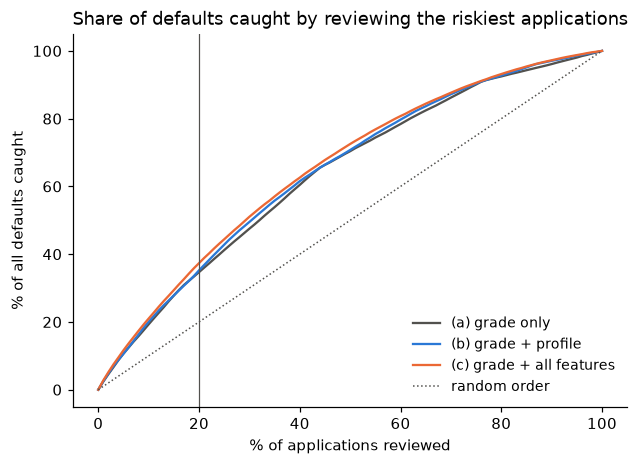

In [9]:
# 3) Capture curve: if the lender reviews the riskiest X% of applications, what share of all defaults is caught?
fig, ax = plt.subplots(figsize=(6.5, 4.4))
share_reviewed = np.linspace(0, 1, 101)
for model, colour in zip(
    ["(a) grade only", "(b) grade + profile", "(c) grade + all features"],
    [GREY, BLUE, ORANGE],
):
    ranked = test.sort_values(model, ascending=False)["default"].to_numpy()
    caught = np.concatenate([[0], np.cumsum(ranked) / ranked.sum()])
    positions = (share_reviewed * len(ranked)).astype(int)
    ax.plot(share_reviewed * 100, caught[positions] * 100, color=colour, label=model)
ax.plot(
    [0, 100], [0, 100], color=GREY, linestyle=":", linewidth=1, label="random order"
)
ax.axvline(REVIEW_SHARE * 100, color=GREY, linewidth=0.8)
ax.set(
    title="Share of defaults caught by reviewing the riskiest applications",
    xlabel="% of applications reviewed",
    ylabel="% of all defaults caught",
)
ax.legend(frameon=False, fontsize=9)
fig.savefig(FIG_DIR / "04_capture_curve.png", dpi=200, bbox_inches="tight")
plt.show()

**Finding.** All models rank risk only moderately (ROC-AUC 0.65–0.68), which is typical for default prediction from application data alone. Flagging the riskiest 20% of applications, grade + all features catches **37.4%** of all defaults, with 27.0% of flagged loans defaulting (about 1.9× the 14.5% base rate); grade alone catches 35.2%. The value of this project is less in a better score and more in *knowing why* a borrower is risky (4.2–4.4) and *who inside a grade* is riskier (4.5).

## 4.7 What should a lender do?

1. **Add an early-warning review step.** Applications matching Part 1b's top rule (2+ recent inquiries + loan above ~29% of income + renter) default at 29.5%, 2.04× the average and 1.40× what their grade predicts. That's about 1% of applications, a manageable number to check by hand (income verification, a smaller loan offer).
2. **Price within a grade by profile.** In grade C, Heavy credit users (22%) and Stretched borrowers (21%) default far more than Established homeowners (15%) at the same interest rate. A profile adjustment inside each grade (higher rate, lower limit, or extra checks) charges for risk the grade misses.
3. **Cap loan size relative to income for credit-seeking applicants.** Loan-to-income is the strongest driver in every profile (odds ×1.38 per standard deviation). Combined with recent credit-seeking, it's the core early-warning pattern, so a lower loan-to-income ceiling for applicants who also opened several accounts recently targets the riskiest borrowers directly.

**Limitations.** One US lender and one economic period (loans issued 2007–2015). Application data only, with no economic conditions (unemployment, interest rates). Two credit features were missing for 2007–2011 loans and median-filled. Predictive power is moderate (ROC-AUC under 0.7), so these are patterns to guide decisions, not a replacement credit score. **Next steps:** add economic indicators, test on other lenders' data, and track whether the profiles stay stable in newer loans.